In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/Users/emmaschima/Desktop/camels_ch/timeseries/observation_based/")
gauge_id = 2263                                     # Chamuerabach (La Punt-Chamues-ch)
camels_file  = folder / f"CAMELS_CH_obs_based_{gauge_id}.csv"
station_file = next(folder.glob("ogd-smn_sam_d_historical*.csv"))
assert camels_file.exists(), f"File not found: {camels_file}"

latitude   = 46.6
hydro_year = 2010                      # 1 Oct 2009 - 30 Sep 2010

col_P, col_T = "precipitation(mm/d)", "temperature_mean(degC)"
col_Tmin, col_Tmax = "temperature_min(degC)", "temperature_max(degC)"
col_Q = "discharge_spec(mm/d)"

# catchment parameters of the model (k and S_max get fitted in block 6)
params = dict(k=0.1, S_max=150.0, T_snow=1.0, DDF=3.0, I_thr=1.0)

In [8]:
df = pd.read_csv(camels_file, parse_dates=["date"], index_col="date")

print("File used:", camels_file.name)
print("Period:", df.index.min().date(), "to", df.index.max().date())
print(df.notna().sum())            # number of valid values per column

for c in [col_T, col_Tmin, col_Tmax]:           # fill short temperature gaps (a NaN would ruin the model)
    df[c] = df[c].interpolate(limit=5)

def hargreaves_pet(tmin, tmean, tmax, doy, lat):
    phi = np.radians(lat)
    dr = 1 + 0.033 * np.cos(2 * np.pi * doy / 365)
    delta = 0.409 * np.sin(2 * np.pi * doy / 365 - 1.39)
    ws = np.arccos(np.clip(-np.tan(phi) * np.tan(delta), -1, 1))
    ra = (24 * 60 / np.pi) * 0.0820 * dr * (
        ws * np.sin(phi) * np.sin(delta) + np.cos(phi) * np.cos(delta) * np.sin(ws))
    pet = 0.0023 * 0.408 * ra * (tmean + 17.8) * np.sqrt(np.clip(tmax - tmin, 0, None))
    return np.clip(pet, 0, None)

df["PET"] = hargreaves_pet(df[col_Tmin], df[col_T], df[col_Tmax],
                           df.index.dayofyear.values, latitude)

File used: CAMELS_CH_obs_based_2263.csv
Period: 1981-01-01 to 2020-12-31
discharge_vol(m3/s)       14610
discharge_spec(mm/d)      14610
waterlevel(m)             14610
precipitation(mm/d)       14610
temperature_min(degC)     14610
temperature_mean(degC)    14610
temperature_max(degC)     14610
rel_sun_dur(%)            14610
swe(mm)                    8157
dtype: int64


In [9]:
## Samedan station precip
st = pd.read_csv(station_file, sep=";")
st["date"] = pd.to_datetime(st["reference_timestamp"], format="%d.%m.%Y %H:%M").dt.normalize()
st["rre150d0"] = pd.to_numeric(st["rre150d0"], errors="coerce")
st = st.drop_duplicates(subset="date").set_index("date").sort_index()
P_station = st["rre150d0"]                                   # mm/d
print("Station covers:", P_station.index.min().date(), "to", P_station.index.max().date())

Station covers: 1979-12-17 to 2025-12-31


In [10]:
## pd selection
d_all = df.loc[f"{hydro_year-2}-10-01":f"{hydro_year}-09-30"].copy()     # warm-up year + hydro year
d_all["P_station"] = P_station.reindex(d_all.index)

for c in [col_P, "P_station", col_T, "PET"]:
    print(f"{c:25s} NaN days: {d_all[c].isna().sum()} of {len(d_all)}")
d_all[col_P] = d_all[col_P].fillna(0)
d_all["P_station"] = d_all["P_station"].fillna(0)

n_q = d_all.loc[f"{hydro_year-1}-10-01":, col_Q].notna().sum()
print("Valid observed Q days in hydro year:", n_q)
if n_q == 0:
    print(df[col_Q].groupby(df.index.year).count())
    raise ValueError("No observed Q in this year - pick another hydro_year")
assert not d_all[[col_P, "P_station", col_T, "PET"]].isna().any().any(), \
    "Model inputs still contain NaN - see counts above (long gaps in T?)"

precipitation(mm/d)       NaN days: 0 of 730
P_station                 NaN days: 0 of 730
temperature_mean(degC)    NaN days: 0 of 730
PET                       NaN days: 0 of 730
Valid observed Q days in hydro year: 365


In [11]:
## model
def run_model(P, T, PET, k=0.1, S_max=150.0, T_snow=1.0, DDF=3.0, I_thr=1.0):
    SWE, S = 0.0, 0.5 * S_max                  # snowpack, flowerpot
    Q, SWE_list = [], []
    for t in range(len(P)):
        # rain or snow
        if T[t] < T_snow:
            snow, rain = P[t], 0.0
        else:
            snow, rain = 0.0, P[t]
        # snow: accumulation and melt
        SWE = SWE + snow
        melt = min(DDF * max(T[t], 0), SWE)
        SWE = SWE - melt
        # interception: first I_thr mm of rain is intercepted and evaporates
        intercepted = min(rain, I_thr)
        through = rain - intercepted
        ET_int = min(intercepted, PET[t])
        PET_left = PET[t] - ET_int             # PET reduced by interception
        if SWE > 0:
            PET_left = 0.0                     # no soil evaporation under snow
        # flowerpot
        S = S + through + melt
        overflow = max(S - S_max, 0)
        S = S - overflow
        ET = min(PET_left * (S / S_max) ** 0.5, S)
        S = S - ET
        q = k * S
        S = S - q
        Q.append(q + overflow)
        SWE_list.append(SWE)
    return np.array(Q), np.array(SWE_list)

def nse(obs, sim):
    ok = ~np.isnan(obs)
    return 1 - np.sum((obs[ok] - sim[ok])**2) / np.sum((obs[ok] - obs[ok].mean())**2)

In [12]:
## catchment params
T, PET = d_all[col_T].values, d_all["PET"].values
in_year = d_all.index >= f"{hydro_year-1}-10-01"        # score only the hydro year, not the warm-up
obs = d_all[col_Q].values

best_nse = -np.inf
for k in [0.02, 0.05, 0.1, 0.2, 0.3]:
    for S_max in [50, 100, 150, 250, 400]:
        q, _ = run_model(d_all[col_P].values, T, PET, **dict(params, k=k, S_max=S_max))
        score = nse(obs[in_year], q[in_year])
        if score > best_nse:
            best_nse, best_k, best_Smax = score, k, S_max
params["k"], params["S_max"] = best_k, best_Smax
print("Chosen parameters:", params, " NSE =", round(best_nse, 2))

Chosen parameters: {'k': 0.05, 'S_max': 400, 'T_snow': 1.0, 'DDF': 3.0, 'I_thr': 1.0}  NSE = 0.69


NSE catchment P: 0.69
NSE station P  : 0.68
Sum P catchment: 998  Sum P station: 667  Sum Q obs: 858 mm


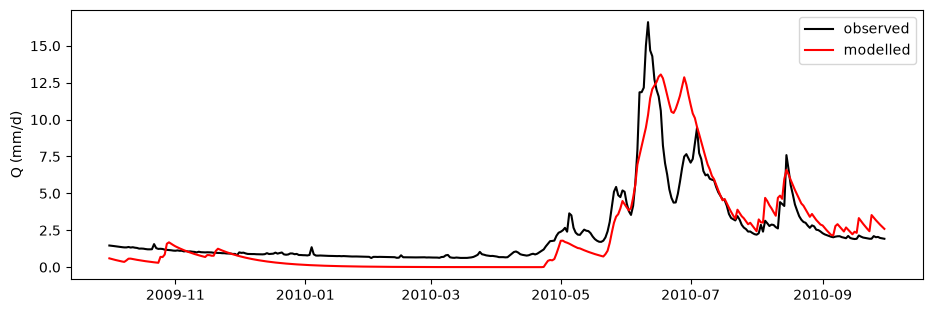

In [13]:
## run w/ catchment P and station P
d_all["Q_catch"], d_all["SWE"] = run_model(d_all[col_P].values, T, PET, **params)
d_all["Q_station"], _          = run_model(d_all["P_station"].values, T, PET, **params)

d = d_all.loc[f"{hydro_year-1}-10-01":].copy()
print("NSE catchment P:", round(nse(d[col_Q].values, d["Q_catch"].values), 2))
print("NSE station P  :", round(nse(d[col_Q].values, d["Q_station"].values), 2))
print("Sum P catchment:", round(d[col_P].sum()), " Sum P station:", round(d["P_station"].sum()),
      " Sum Q obs:", round(d[col_Q].sum()), "mm")

# quick check: modeled Q must be visible here
plt.figure(figsize=(11, 3.5))
plt.plot(d.index, d[col_Q], "k", label="observed")
plt.plot(d.index, d["Q_catch"], "r", label="modelled")
plt.ylabel("Q (mm/d)"); plt.legend(); plt.show()

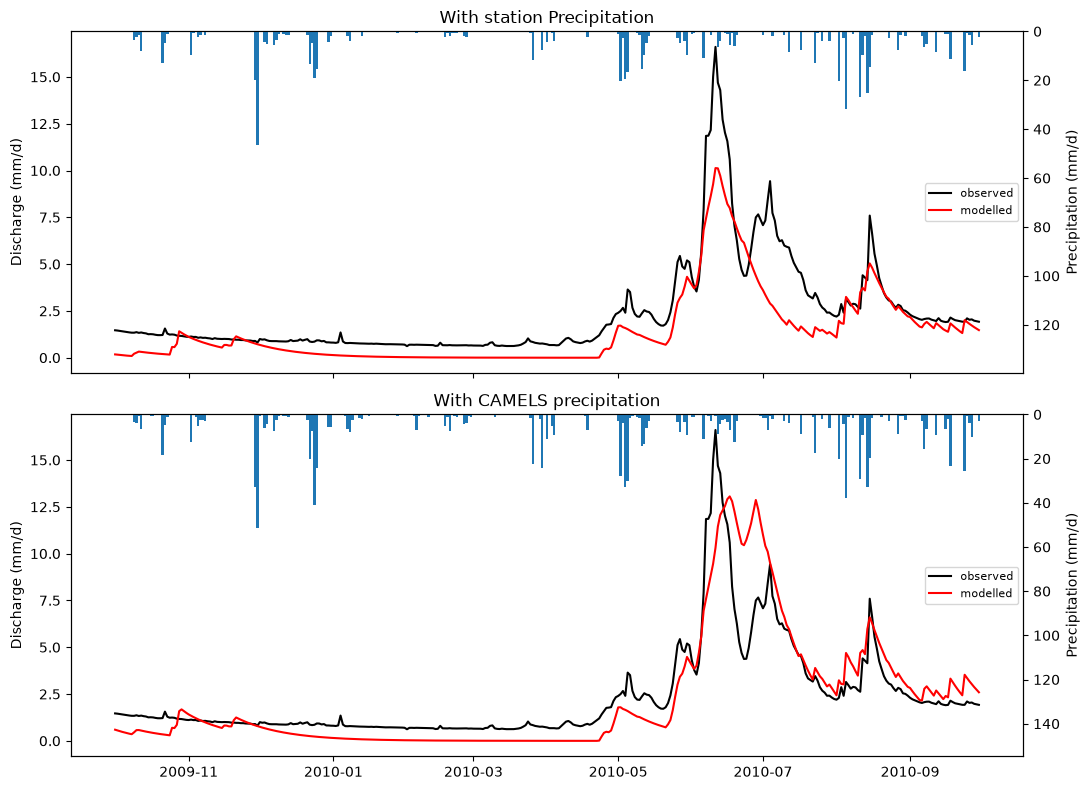

In [18]:
def plot_q(ax, data, pcol, qcol, title):
    ax.plot(data.index, data[col_Q], "k", label="observed")
    ax.plot(data.index, data[qcol], "r", label="modelled")
    ax.set_ylabel("Discharge (mm/d)")
    ax.set_title(title)
    ax.legend(loc="center right", fontsize=8)
    ax2 = ax.twinx()
    ax2.bar(data.index, data[pcol], color="tab:blue", width=1.0)
    ax2.set_ylim(data[pcol].max() * 3, 0)              # reversed: rain hangs from the top
    ax2.set_ylabel("Precipitation (mm/d)")

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
plot_q(axes[0], d, "P_station", "Q_station", "With station Precipitation")
plot_q(axes[1], d, col_P, "Q_catch", "With CAMELS precipitation")
plt.tight_layout(); plt.savefig("fig_year.png", dpi=150); plt.show()

Good window ends: 2010-07-24 | bad window ends: 2010-07-01


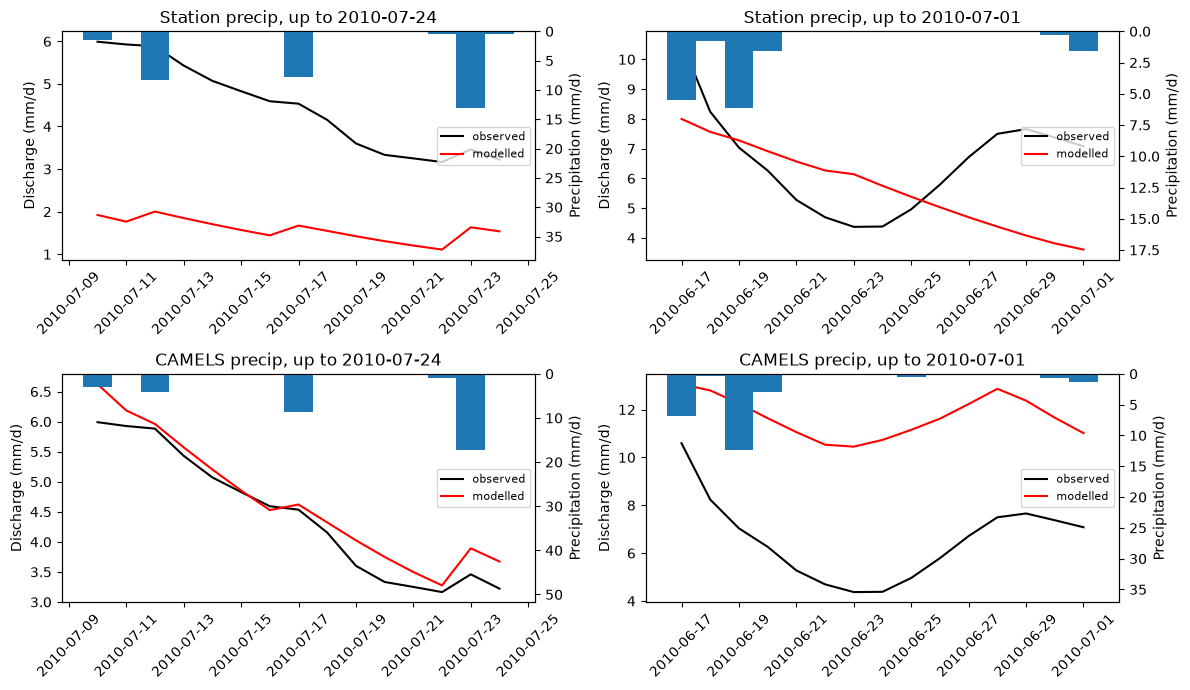

In [15]:
err = (d[col_Q] - d["Q_catch"]).abs().rolling(14, min_periods=10).mean()
err = err.where(d[col_Q].rolling(14, min_periods=10).mean() > d[col_Q].mean())
if err.notna().sum() == 0:
    raise ValueError("No valid 14-day window - check NaN in Q_catch / observed Q")
good_end, bad_end = err.idxmin(), err.idxmax()
print("Good window ends:", good_end.date(), "| bad window ends:", bad_end.date())

events = [good_end, bad_end]       # or type your own: pd.Timestamp("2010-06-15")
fig, axs = plt.subplots(2, len(events), figsize=(6 * len(events), 7), squeeze=False)
for j, end in enumerate(events):
    w = d.loc[end - pd.Timedelta(days=14): end]
    plot_q(axs[0, j], w, "P_station", "Q_station", "Station precip, up to " + str(end.date()))
    plot_q(axs[1, j], w, col_P, "Q_catch", "CAMELS precip, up to " + str(end.date()))
    axs[0, j].tick_params(axis="x", rotation=45)
    axs[1, j].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("fig_events.png", dpi=150); plt.show()

Overlap: 1981-01-01 to 2020-12-31 -> 14610 days
Mean annual P: station 692 mm | CAMELS 1005 mm   (both mm/d, so units match)


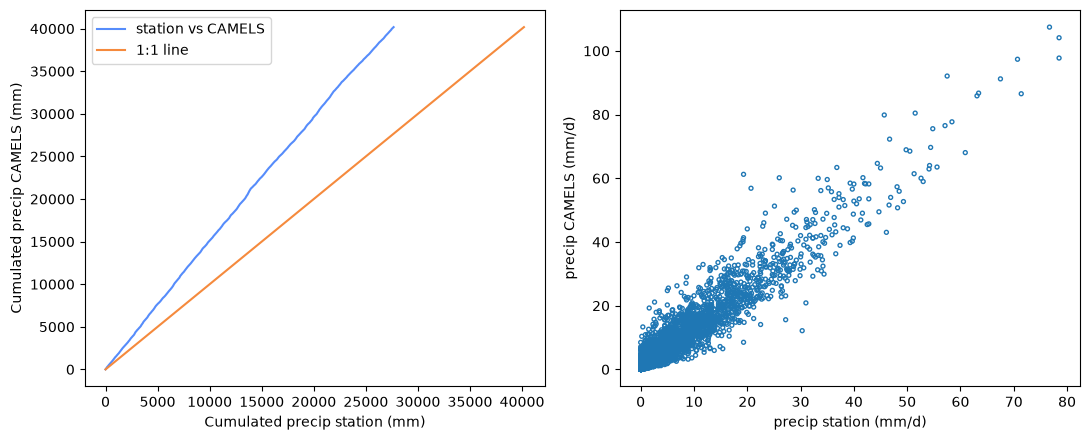

In [16]:
both = pd.concat([df[col_P], P_station], axis=1, join="inner").dropna()
both.columns = ["camels", "station"]
print("Overlap:", both.index.min().date(), "to", both.index.max().date(), "->", len(both), "days")
print("Mean annual P: station", round(both["station"].mean() * 365.25), "mm | CAMELS",
      round(both["camels"].mean() * 365.25), "mm   (both mm/d, so units match)")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.5))
cs, cc = both["station"].cumsum(), both["camels"].cumsum()
a.plot(cs, cc, label="station vs CAMELS")
m = max(cs.max(), cc.max())
a.plot([0, m], [0, m], label="1:1 line")
a.set_xlabel("Cumulated precip station (mm)"); a.set_ylabel("Cumulated precip CAMELS (mm)")
a.legend()
b.scatter(both["station"], both["camels"], s=8, facecolors="none", edgecolors="tab:blue")
b.set_xlabel("precip station (mm/d)"); b.set_ylabel("precip CAMELS (mm/d)")
plt.tight_layout(); plt.savefig("fig_precip_comparison.png", dpi=150); plt.show()

SWE columns in CAMELS: ['swe(mm)']


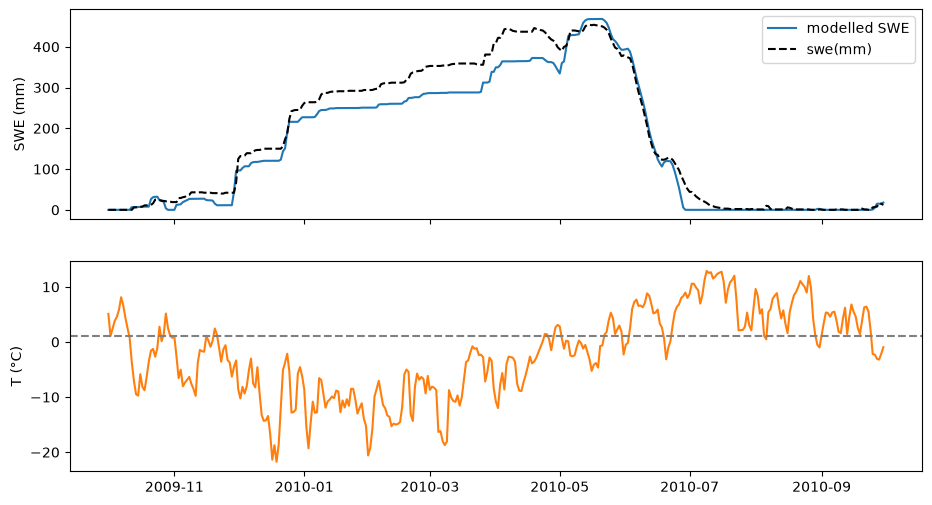

Fraction of P falling as snow: 0.6
Max SWE: 468 mm on 2010-05-20
No snow module (all rain): NSE = -0.2

DDF  T_snow  NSE  maxSWE
1    0.0    0.16 585
1    1.0    -0.28 648
1    2.0    -0.35 650
2    0.0    0.71 585
2    1.0    0.49 648
2    2.0    0.43 648
3    0.0    0.72 584
3    1.0    0.69 647
3    2.0    0.67 647
4    0.0    0.77 584
4    1.0    0.7 647
4    2.0    0.67 647
5    0.0    0.73 583
5    1.0    0.78 646
5    2.0    0.77 646
6    0.0    0.64 582
6    1.0    0.77 645
6    2.0    0.78 645


In [17]:
## snow tests
fig, (a, b) = plt.subplots(2, 1, sharex=True, figsize=(11, 6))
a.plot(d.index, d["SWE"], "tab:blue", label="modelled SWE")
swe_cols = [c for c in df.columns if "swe" in c.lower()]      # CAMELS may contain its own SWE
print("SWE columns in CAMELS:", swe_cols)
for c in swe_cols:
    a.plot(d.index, df[c].reindex(d.index), "k--", label=c)
a.set_ylabel("SWE (mm)"); a.legend()
b.plot(d.index, d[col_T], "tab:orange"); b.axhline(params["T_snow"], color="gray", ls="--")
b.set_ylabel("T (°C)"); plt.show()

print("Fraction of P falling as snow:", round(d.loc[d[col_T] < params["T_snow"], col_P].sum() / d[col_P].sum(), 2))
print("Max SWE:", round(d["SWE"].max()), "mm on", d["SWE"].idxmax().date())

def nse_for(**kw):
    q, s = run_model(d_all[col_P].values, T, PET, **dict(params, **kw))
    q = pd.Series(q, index=d_all.index).loc[d.index].values
    return round(nse(d[col_Q].values, q), 2), round(s.max())

print("No snow module (all rain): NSE =", nse_for(T_snow=-99)[0])
print("\nDDF  T_snow  NSE  maxSWE")
for DDF in [1, 2, 3, 4, 5, 6]:
    for T_snow in [0.0, 1.0, 2.0]:
        print(DDF, "  ", T_snow, "  ", *nse_for(DDF=DDF, T_snow=T_snow))